# F4, F5, F6, F8: occupations, k-point weights, spectrum normalization (all implemented)

| finding | what | checked here with |
|---|---|---|
| F4 | `fillings` dump is ×2 for `spintype no-spin`, while computed occupations are in [0,1] | `N2_nospin` (legacy vs. fixed) and the z-spin N2 pair |
| F5 | symmetry-reduced meshes average single atoms/bonds/m-orbitals; `get_wk_t` dropped symmetry weights | `graphene_zspin_full` vs. `graphene_zspin_symm` |
| F6 | Gaussian kernel unnormalized; LTI applies 1/N_k twice | DOS integrals, legacy vs. fixed, for N2 and graphene |
| F8 | occupations without a `fillings` file: Gauss/MP1 crash on arrays, `Cold` rejected, step function inverted, no mu without smearing | the helpers vs. `ElecInfo::smear`; computed vs. dumped fillings for Al (four smearings) and Si (no smearing) |

Each section detects whether its fix has landed, from the legacy switch (F4–F6) or from behaviour (F8). Known-bug
checks document the current state and stop being reached once the fix lands.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs.general import SIGMA_DEFAULT
from scipy.special import erfc
from scipy.integrate import trapezoid
from crawfish.funcs import get_dos
from crawfish.io.data_parsing import get_wk_t
from crawfish.core import elecdata as ed_mod
from crawfish.utils.testing import EXAMPLE_CALC_DIRS_DIR

print({f: fix_available(f) for f in ["F4", "F5", "F6"]})

{'F4': True, 'F5': True, 'F6': True}


## F6: spectrum normalization (implemented)

**Finding:** the Gaussian kernel $e^{-(E-\epsilon)^2/\sigma}$ was unnormalized (it integrated to
$\sqrt{\pi\sigma}$ per state). For LTI, libtetrabz weights already contain the $1/N_k$ of the Brillouin-zone
average, and crawfish multiplied them by $w_t$ again. The two methods gave different, arbitrary scales.

**Fix:** divide the Gaussian by $\sqrt{\pi\sigma}$ (same shape and same `sig`), and multiply LTI weights by
$N_k$. Spectra are now densities per Hartree, and the total DOS integrates to $\sum_t w_t\, n_\text{bands}$.
**Legacy switch:** `legacy_normalization=True`.

The comparison uses N2 (flat molecular bands, which LTI resolves only roughly) and graphene on the full 12×12 mesh
(dispersive).

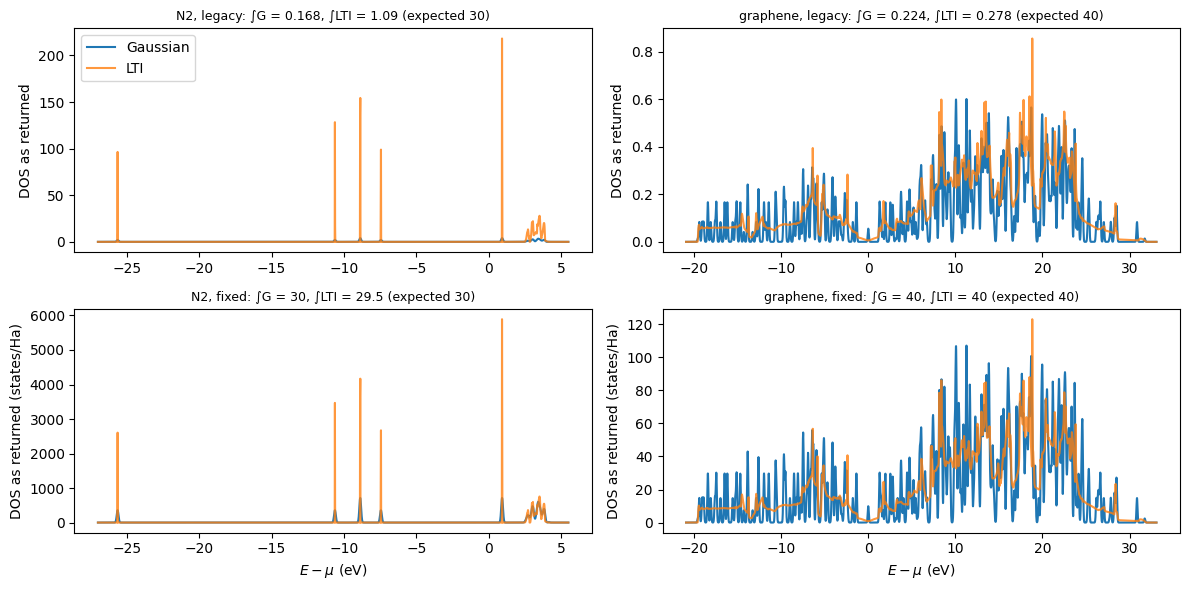

expected  ∫ Gaussian DOS  ∫ LTI DOS
system   version                                     
N2       legacy       30.0          0.1681   1.093600
         fixed        30.0         30.0000  29.526800
graphene legacy       40.0          0.2242   0.277800
         fixed        40.0         40.0000  40.001598

In [2]:
norm_systems = {"N2": N2_CALC_DIR, "graphene": Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_full"}
rows, curves = [], {}
for name, calc_dir in norm_systems.items():
    for fixed in (False, True):
        ed = load_edata_at("F6", fixed=fixed, calc_dir=calc_dir)
        er = np.arange(ed.e_tj.min() - 0.05, ed.e_tj.max() + 0.05, 0.0005, dtype=np.float32)
        np.random.seed(0)  # rattle_eigenvals is random
        g = np.asarray(get_dos(ed, erange=er)[1])
        l = np.asarray(get_dos(ed, erange=er, lti=True, rattle_eigenvals=True)[1])
        tag = "fixed" if fixed else "legacy"
        curves[(name, tag)] = (to_ev_rel_mu(ed, er), g, l)
        rows.append({"system": name, "version": tag, "expected": float(ed.wk_t.sum() * ed.nbands),
                     "∫ Gaussian DOS": trapezoid(g, er), "∫ LTI DOS": trapezoid(l, er)})
norm_table = pd.DataFrame(rows).set_index(["system", "version"])

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for col, name in enumerate(norm_systems):
    for row, tag in enumerate(["legacy", "fixed"]):
        x, g, l = curves[(name, tag)]
        ax = axes[row, col]
        ax.plot(x, g, label="Gaussian")
        ax.plot(x, l, alpha=0.8, label="LTI")
        ax.set_title(f"{name}, {tag}: ∫G = {norm_table.loc[(name, tag), '∫ Gaussian DOS']:.3g}, "
                     f"∫LTI = {norm_table.loc[(name, tag), '∫ LTI DOS']:.3g} (expected {norm_table.loc[(name, tag), 'expected']:.0f})",
                     fontsize=9)
        ax.set_ylabel("DOS as returned" + (" (states/Ha)" if tag == "fixed" else ""))
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel(r"$E - \mu$ (eV)")
fig.tight_layout()
savefig(fig, "F6_dos_normalization")
plt.show()
norm_table.round(4)

## F8: occupations without a `fillings` file (implemented)

**Finding:** `ElecData.occ_tj` computes occupations from the eigenvalues when no `fillings` file was dumped. Of
its helpers, only Fermi worked: Gauss and MP1 called `math.erf` on arrays (TypeError), JDFTx's spelling `Cold` was
rejected as unknown, and the no-smearing step `np.heaviside(eig, mu)` filled every state above 0 Ha. A JDFTx run
without smearing also prints no mu, so that path crashed before reaching the step.

**Fix:** the helpers use `scipy.special.erfc` and match `ElecInfo.cpp::ElecInfo::smear`, with
$x = (\varepsilon-\mu)/(2\sigma)$. Broadening types are matched case-insensitively. Without smearing,
crawfish uses JDFTx's constant fillings (`ElecInfo::setup`): the lowest bands of each state hold $N/2$ electrons
(no-spin) or $(N \pm M)/2$ (z-spin, $M$ = `elec-initial-magnetization`), which needs no mu. No legacy switch:
the old paths only crashed or gave nonsense (notes section 4.0).

First the helpers on an array, against JDFTx's formulas (reference dashed).

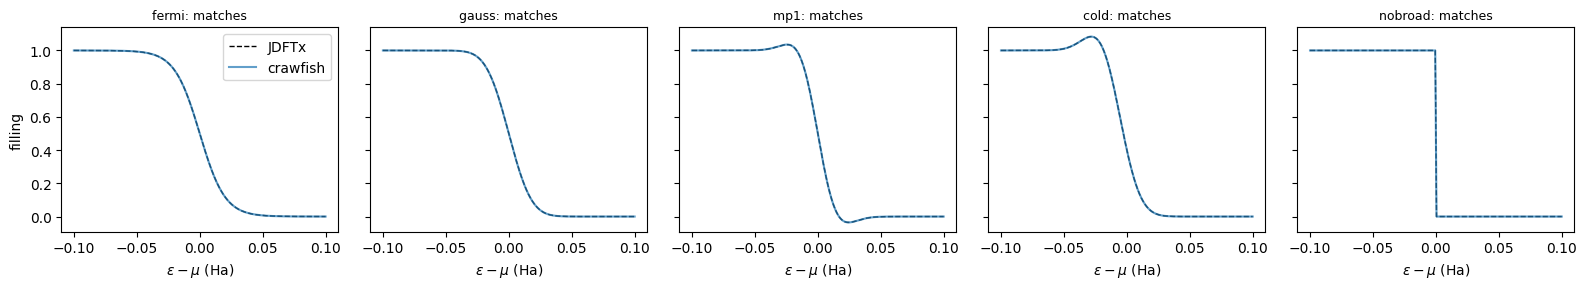

{'fermi': 'matches',
 'gauss': 'matches',
 'mp1': 'matches',
 'cold': 'matches',
 'nobroad': 'matches'}

In [3]:
mu, sigma = 0.0, 0.01
eps = np.linspace(-0.1, 0.1, 401)
xx = (eps - mu) / (2 * sigma)
jdftx = {
    "fermi": 0.5 * (1 - np.tanh(xx)),
    "gauss": 0.5 * erfc(xx),
    "mp1": 0.5 * erfc(xx) - xx * np.exp(-xx**2) / (2 * np.sqrt(np.pi)),
    "cold": 0.5 * erfc(xx + np.sqrt(0.5)) + np.exp(-(xx + np.sqrt(0.5)) ** 2) / np.sqrt(2 * np.pi),
    "nobroad": np.heaviside(mu - eps, 0.5),
}
status = {}
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (name, ref_f) in zip(axes, jdftx.items()):
    ax.plot(eps, ref_f, "k--", lw=1, label="JDFTx")
    try:
        got = getattr(ed_mod, f"calculate_filling_{name}")(sigma, eps, mu)
        ax.plot(eps, got, alpha=0.7, label="crawfish")
        status[name] = "matches" if np.allclose(got, ref_f, atol=1e-8) else "differs"
    except Exception as err:
        status[name] = f"raises {type(err).__name__}"
    ax.set_title(f"{name}: {status[name]}", fontsize=9)
    ax.set_xlabel(r"$\varepsilon - \mu$ (Ha)")
axes[0].set_ylabel("filling")
axes[0].legend()
fig.tight_layout()
savefig(fig, "F8_filling_helpers")
plt.show()
status

Then the occupations `ElecData.occ_tj` computes without the `fillings` file, against the file, for fcc Al
with each smearing type (0.01 Ha, many fractional fillings) and diamond Si without smearing (no-spin, and z-spin
constrained to $M = 2$, where the spin-up HOMO lies above the spin-down LUMO).

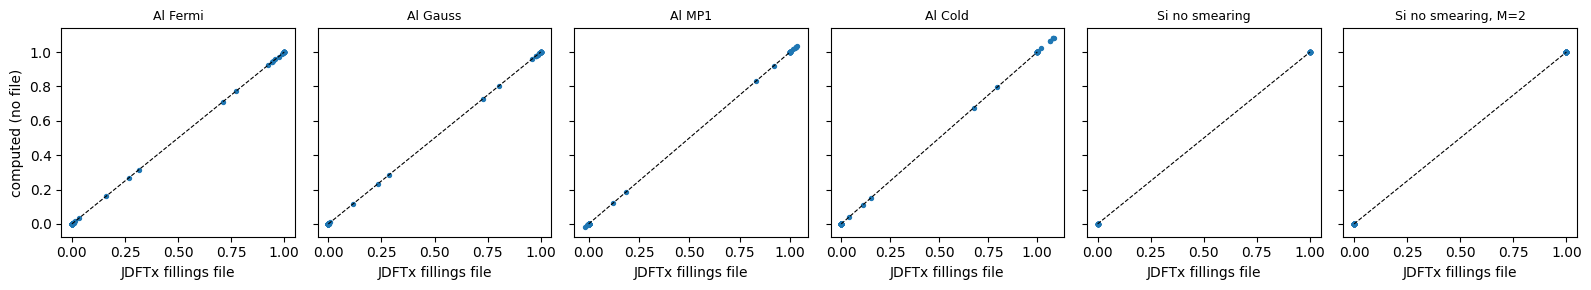

,smearing,N_e (outfile),N_e (computed),max |computed - file|
calculation,,,,
Al Fermi,Fermi,3.0,3.0,0.000022
Al Gauss,Gauss,3.0,3.0,0.000009
Al MP1,MP1,3.0,3.0,0.000006
Al Cold,Cold,3.0,3.0,0.000003
Si no smearing,NaN,8.0,8.0,0.000000
"Si no smearing, M=2",NaN,8.0,8.0,0.000000


In [4]:
f8_dirs = {f"Al {t}": f"Al_fcc_{t}" for t in ["Fermi", "Gauss", "MP1", "Cold"]}
f8_dirs.update({"Si no smearing": "Si_nosmear_nospin", "Si no smearing, M=2": "Si_nosmear_zspin_M2"})
f8_rows, f8_pairs = [], {}
for label, name in f8_dirs.items():
    ed = load_edata(Path(EXAMPLE_CALC_DIRS_DIR) / name)
    from_file = ed.occ_tj.copy()
    ed.fillingsfile_filepath, ed._occ_tj = None, None
    try:
        computed = np.asarray(ed.occ_tj)
        err = float(np.abs(computed - from_file).max())
        f8_pairs[label] = (from_file.ravel(), computed.ravel())
        n_e = float(np.sum(ed.wk_t[:, None] * computed))
    except Exception as exc:
        err, n_e = f"raises {type(exc).__name__}", np.nan
    f8_rows.append({"calculation": label, "smearing": ed.outfile.broadening_type,
                    "N_e (outfile)": ed.outfile.total_electrons, "N_e (computed)": n_e,
                    "max |computed - file|": err})
f8_table = pd.DataFrame(f8_rows).set_index("calculation")

fig, axes = plt.subplots(1, len(f8_dirs), figsize=(16, 3), sharey=True)
for ax, label in zip(axes, f8_dirs):
    if label in f8_pairs:
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        ax.scatter(*f8_pairs[label], s=8)
    else:
        ax.text(0.5, 0.5, f8_table.loc[label, "max |computed - file|"], ha="center", transform=ax.transAxes)
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("JDFTx fillings file")
axes[0].set_ylabel("computed (no file)")
fig.tight_layout()
savefig(fig, "F8_fillings_vs_jdftx")
plt.show()
f8_table

## F4: fillings files for spin-unpolarized calculations (implemented)

**Finding:** JDFTx's `Dump.cpp` writes `fillings` as 2 × its internal [0, 1] fillings for `spintype no-spin`, and
its k-point weights already sum to 2. Read as-is, the file double-counts electrons. **Fix:** `ElecData.occ_tj`
divides the file by `spin_weight`, and integrated spectra no longer divide occupations by their maximum (that
rescaling hid the factor 2 for integrated spectra, but not for the density matrix behind pCOBI). **Legacy
switch:** `legacy_fillings=True`.

`N2_nospin` is a gas-phase N2 calculation run locally for this (same geometry as `N2_bare_min`, no-spin, 2×2×2).
`N2_bare_min` and `N2_no_fillings` are the same z-spin calculation with and without a `fillings` file. z-spin
fillings aren't doubled, so they check that the fix leaves spin-polarized data alone.

raw no-spin fillings file: max 2.0


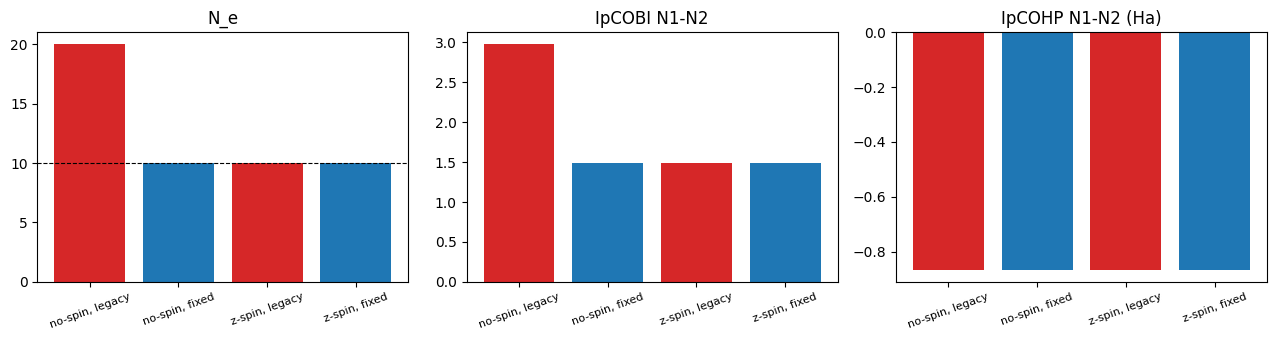

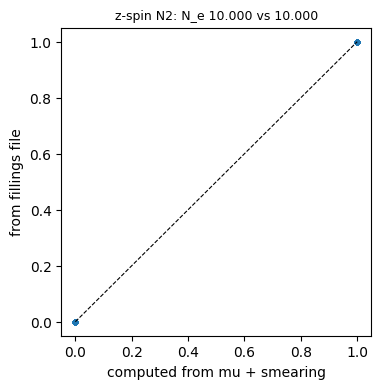

,N_e,N_e (outfile),max occupation,IpCOBI N1-N2,IpCOHP N1-N2 (Ha)
"no-spin, legacy",20.0,10.0,2.0,2.97762,-0.86680
"no-spin, fixed",10.0,10.0,1.0,1.48881,-0.86680
"z-spin, legacy",10.0,10.0,1.0,1.49349,-0.86678
"z-spin, fixed",10.0,10.0,1.0,1.49349,-0.86678


In [5]:
from crawfish.funcs import get_ipcobi, get_ipcohp

ne = lambda ed: float(np.sum(ed.wk_t[:, None].astype(np.float64) * ed.occ_tj))
last = lambda func, ed: last_value(func(ed, idcs1=0, idcs2=1, use_cache=False))
print("raw no-spin fillings file: max", np.fromfile(N2_NOSPIN_CALC_DIR / "fillings").max())

versions = {
    "no-spin, legacy": load_edata_at("F4", fixed=False, calc_dir=N2_NOSPIN_CALC_DIR),
    "no-spin, fixed": load_edata_at("F4", fixed=True, calc_dir=N2_NOSPIN_CALC_DIR),
    "z-spin, legacy": load_edata_at("F4", fixed=False),
    "z-spin, fixed": load_edata_at("F4", fixed=True),
}
f4_table = pd.DataFrame({
    name: {"N_e": ne(ed), "N_e (outfile)": ed.outfile.total_electrons, "max occupation": float(ed.occ_tj.max()),
           "IpCOBI N1-N2": last(get_ipcobi, ed), "IpCOHP N1-N2 (Ha)": last(get_ipcohp, ed)}
    for name, ed in versions.items()
}).T

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
colors = ["C3", "C0", "C3", "C0"]
for ax, col in zip(axes, ["N_e", "IpCOBI N1-N2", "IpCOHP N1-N2 (Ha)"]):
    ax.bar(range(len(f4_table)), f4_table[col], color=colors)
    ax.set_xticks(range(len(f4_table)), f4_table.index, rotation=20, fontsize=8)
    ax.set_title(col)
axes[0].axhline(10, color="k", ls="--", lw=0.8)
fig.tight_layout()
savefig(fig, "F4_nospin_fillings")
plt.show()

with_file, without_file = load_edata(), load_edata(Path(EXAMPLE_CALC_DIRS_DIR) / "N2_no_fillings")
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(without_file.occ_tj.ravel(), with_file.occ_tj.ravel(), s=8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("computed from mu + smearing")
ax.set_ylabel("from fillings file")
ax.set_title(f"z-spin N2: N_e {ne(with_file):.3f} vs {ne(without_file):.3f}", fontsize=9)
savefig(fig, "F4_occupations_zspin")
plt.show()
f4_table.round(5)

## F5: symmetry-reduced k-meshes (implemented)

**Finding:** with JDFTx's default `symmetries automatic`, only the irreducible k-points are computed. Each one
stands in for its symmetry-equivalent k-points, which belong to other, equivalent atoms, bonds and m-orbitals.
Quantities for one atom, bond or m-orbital are then averaged over their equivalent copies. Only selections the
point group maps onto themselves come out exact: the sum over all lattice images, complete orbital shells and
complete sets of equivalent atoms. Separately, `get_wk_t` discarded JDFTx's symmetry weights for spin-polarized
reduced meshes.

**Fix:**
- JDFTx's weights are used. If `kPts` is missing, they come from the `bandProjections` header.
- Single-image pair spectra (including R = 0) raise on a reduced mesh.
- `image="all"` pair spectra and atom/orbital-subset pDOS warn.

**Legacy switch:** `legacy_reduced_kmesh=True`.

**Time-reversal unfolding (default, `ElecData.unfold_time_reversal`):** a mesh reduced only by k ↔ −k is unfolded
onto the full mesh exactly, using T(−k) = T(k)* for collinear calculations. JDFTx produces such a mesh with
`symmetries manual` and only the identity matrix, at about half the cost of `symmetries none`.

`graphene_zspin_full`, `graphene_zspin_symm` and `graphene_zspin_tr` are the same z-spin graphene calculation
(12×12×1 mesh, 20 bands), run with `symmetries none` (144 k per spin), `symmetries automatic` (19 k per spin) and
identity-only `symmetries manual` (74 k per spin, unfolded to 144).

time-reversal run unfolded: True (148 computed states -> 288)


/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:1297: UserWarning: WARNING: Internal inconsistency found with respect to input parameters (nSpin * nk-pts != nStates).
  self._lti_allowed = _get_lti_allowed(self.bandfile_header_filepath, self.outfile_filepath)
/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:1182: UserWarning: Kpts file does not match expected number of k-points. k-point weights will be meaningless.
  self._wk_t = get_wk_t(


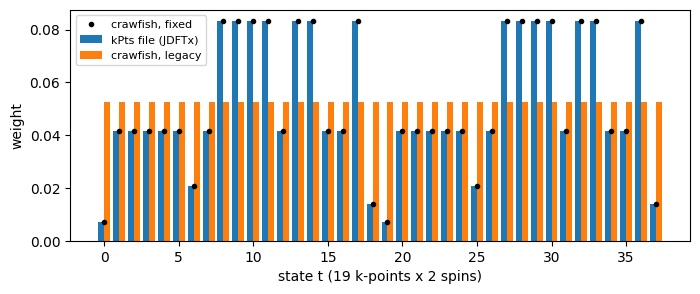

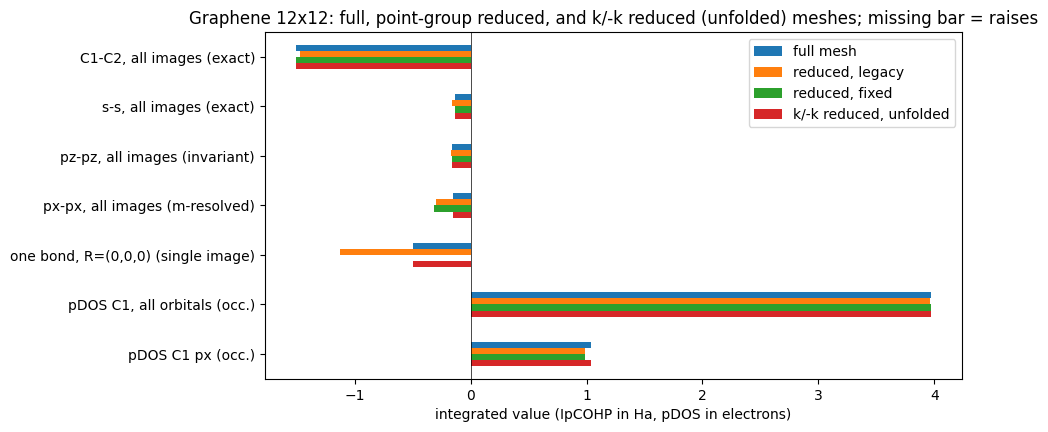

get_ipcohp(reduced mesh, default image='nearest') raises:
  pCOHP for a single lattice image (image='nearest') can't be recovered from a k-mesh reduced by symmetry: every k-point stands in for its symmetry-equivalent ones, which belong to other, equivalent bonds. Use image='all' (exact when summed over symmetry-equivalent atoms and complete orbital shells). Rerun JDFTx with 'symmetries none' for atom-, bond- or orbital-resolved results (notes/theory_audit.md, F5).


,full mesh,"reduced, legacy","reduced, fixed","k/-k reduced, unfolded"
"C1-C2, all images (exact)",-1.50268,-1.47588,-1.50264,-1.50265
"s-s, all images (exact)",-0.13667,-0.16354,-0.13667,-0.13667
"pz-pz, all images (invariant)",-0.16319,-0.16941,-0.16319,-0.16319
"px-px, all images (m-resolved)",-0.14881,-0.30163,-0.31527,-0.14880
"one bond, R=(0,0,0) (single image)",-0.50127,-1.12406,NaN,-0.50126
"pDOS C1, all orbitals (occ.)",3.96690,3.96426,3.96681,3.96680
pDOS C1 px (occ.),1.03893,0.99023,0.98570,1.03889


In [6]:
import warnings
from crawfish.funcs.pcohp import _get_pcohp_tj
from crawfish.funcs.dos import get_pdos_tj
from crawfish.utils.indexing import get_orb_idcs
from crawfish.io.data_parsing import parse_kptsfile

GR_FULL = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_full"
GR_SYMM = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_symm"
GR_TR = Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_tr"
gr = {
    "full mesh": load_edata_at("F5", fixed=True, calc_dir=GR_FULL),
    "reduced, legacy": load_edata_at("F5", fixed=False, calc_dir=GR_SYMM),
    "reduced, fixed": load_edata_at("F5", fixed=True, calc_dir=GR_SYMM),
    "k/-k reduced, unfolded": load_edata_at("F5", fixed=True, calc_dir=GR_TR),
}
print("time-reversal run unfolded:", gr["k/-k reduced, unfolded"].time_reversal_unfolded,
      f"({gr['k/-k reduced, unfolded'].nstates_file} computed states -> {gr['k/-k reduced, unfolded'].nstates})")

def icohp(ed, image, o=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.sum(ed.occ_tj * _get_pcohp_tj(ed, 0, None, o, 1, None, o, use_cache=False, image=image)))

def occ_pdos(ed, idcs, orbs):
    return float(np.sum(ed.occ_tj * get_pdos_tj(ed.proj_tju, get_orb_idcs(ed, idcs, None, orbs), ed.wk_t)))

# The weights themselves
file_w = np.array(parse_kptsfile(GR_SYMM / "kPts")[0])
fig, ax = plt.subplots(figsize=(8, 3))
idx = np.arange(len(file_w))
ax.bar(idx - 0.2, file_w, 0.4, label="kPts file (JDFTx)")
ax.bar(idx + 0.2, gr["reduced, legacy"].wk_t, 0.4, label="crawfish, legacy")
ax.plot(idx, gr["reduced, fixed"].wk_t, "k.", label="crawfish, fixed")
ax.set_xlabel("state t (19 k-points x 2 spins)")
ax.set_ylabel("weight")
ax.legend(fontsize=8)
savefig(fig, "F5_reduced_mesh_weights")
plt.show()

# What survives the reduction. "full mesh" is the reference; legacy runs unguarded with uniform weights
rows = {
    "C1-C2, all images (exact)": lambda ed: icohp(ed, "all"),
    "s-s, all images (exact)": lambda ed: icohp(ed, "all", "s"),
    "pz-pz, all images (invariant)": lambda ed: icohp(ed, "all", "pz"),
    "px-px, all images (m-resolved)": lambda ed: icohp(ed, "all", "px"),
    "one bond, R=(0,0,0) (single image)": lambda ed: icohp(ed, [0, 0, 0]),
    "pDOS C1, all orbitals (occ.)": lambda ed: occ_pdos(ed, 0, None),
    "pDOS C1 px (occ.)": lambda ed: occ_pdos(ed, 0, "px"),
}
f5_table = pd.DataFrame({name: {row: func(ed) for row, func in rows.items()}
                         for name, ed in [("full mesh", gr["full mesh"]), ("reduced, legacy", gr["reduced, legacy"])]})
# Fixed crawfish: same numbers where exact, but single images raise
fixed_vals = {}
for row, func in rows.items():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fixed_vals[row] = func(gr["reduced, fixed"])
    except ValueError:
        fixed_vals[row] = np.nan  # raised
f5_table["reduced, fixed"] = pd.Series(fixed_vals)
f5_table["k/-k reduced, unfolded"] = pd.Series({row: func(gr["k/-k reduced, unfolded"]) for row, func in rows.items()})

ax = f5_table.plot.barh(figsize=(9, 4.5))
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("integrated value (IpCOHP in Ha, pDOS in electrons)")
ax.set_title("Graphene 12x12: full, point-group reduced, and k/-k reduced (unfolded) meshes; missing bar = raises")
ax.invert_yaxis()
savefig(ax.figure, "F5_reduced_mesh_quantities")
plt.show()

try:
    from crawfish.funcs import get_ipcohp
    get_ipcohp(gr["reduced, fixed"], idcs1=0, idcs2=1)
except ValueError as err:
    print("get_ipcohp(reduced mesh, default image='nearest') raises:\n ", err)
f5_table.round(5)

## Tests

In [7]:
# F6: both methods integrate to the state count after the fix; legacy scales were sqrt(pi*sig) and 1/N_k
assert fix_available("F6")
for name in norm_systems:
    fixed, legacy = norm_table.loc[(name, "fixed")], norm_table.loc[(name, "legacy")]
    assert np.isclose(fixed["∫ Gaussian DOS"], fixed["expected"], rtol=1e-4)
    assert np.isclose(legacy["∫ Gaussian DOS"], legacy["expected"] * np.sqrt(np.pi * SIGMA_DEFAULT), rtol=1e-4)
g = norm_table.loc[("graphene", "fixed")]
assert np.isclose(g["∫ LTI DOS"], g["expected"], rtol=1e-3)  # dispersive bands: LTI is accurate
assert np.isclose(norm_table.loc[("N2", "fixed"), "∫ LTI DOS"], 30, rtol=0.02)  # flat bands: approximate

# F8: helpers match ElecInfo::smear; occupations computed without the file match JDFTx's dump
assert all(v == "matches" for v in status.values()), status
assert len(f8_pairs) == len(f8_dirs), f8_table
for label, (from_file, computed) in f8_pairs.items():
    assert np.allclose(computed, from_file, atol=5e-5), label
assert np.allclose(f8_table["N_e (computed)"], f8_table["N_e (outfile)"], atol=1e-3)

# F4: no-spin fillings halved (legacy double-counts), z-spin untouched, file and computed occupations agree
assert fix_available("F4")
assert np.isclose(f4_table.loc["no-spin, fixed", "N_e"], 10, atol=1e-3)
assert np.isclose(f4_table.loc["no-spin, legacy", "N_e"], 20, atol=1e-3)
assert np.isclose(f4_table.loc["no-spin, legacy", "IpCOBI N1-N2"], 2 * f4_table.loc["no-spin, fixed", "IpCOBI N1-N2"], rtol=1e-5)
assert np.allclose(f4_table.loc["z-spin, legacy"], f4_table.loc["z-spin, fixed"], atol=1e-6)
assert np.isclose(f4_table.loc["no-spin, fixed", "IpCOBI N1-N2"], f4_table.loc["z-spin, fixed", "IpCOBI N1-N2"], rtol=0.01)
assert np.isclose(ne(with_file), ne(without_file), atol=1e-3)

# F5: JDFTx weights used; exact quantities agree with the full mesh; single images raise; legacy was wrong
assert fix_available("F5")
assert np.allclose(gr["reduced, fixed"].wk_t, file_w) and np.allclose(gr["reduced, legacy"].wk_t, gr["reduced, legacy"].wk_t[0])
for row in ["C1-C2, all images (exact)", "s-s, all images (exact)", "pz-pz, all images (invariant)", "pDOS C1, all orbitals (occ.)"]:
    assert np.isclose(f5_table.loc[row, "reduced, fixed"], f5_table.loc[row, "full mesh"], atol=2e-4), row
assert np.isnan(f5_table.loc["one bond, R=(0,0,0) (single image)", "reduced, fixed"])
assert abs(f5_table.loc["one bond, R=(0,0,0) (single image)", "reduced, legacy"] - f5_table.loc["one bond, R=(0,0,0) (single image)", "full mesh"]) > 0.3
# Time-reversal unfolding reproduces the full mesh for every quantity, including single bonds and m-resolved ones
assert gr["k/-k reduced, unfolded"].time_reversal_unfolded
assert np.allclose(f5_table["k/-k reduced, unfolded"], f5_table["full mesh"], atol=3e-4)
print("All F4-F8 checks passed.")

All F4-F8 checks passed.
